In [2]:
# ============================================
# 1. IMPORT LIBRARIES AND LOAD DATA
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Load the cleaned dataset already uploaded to Colab
df = pd.read_csv("used_cars_cleaned.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (202316, 18)


,price,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,drive,type,paint_color,state,seller_type,car_age,mileage_per_year,is_luxury
0,27999.0,2022.0,ford,explorer st,excellent,6 cylinders,gas,99179.0,clean,automatic,4wd,SUV,grey,ca,dealer,4.0,19835.800000,0.0
1,2200.0,1969.0,volkswagen,bug,fair,4 cylinders,gas,90000.0,clean,manual,rwd,other,green,ca,owner,57.0,1551.724138,0.0
2,15999.0,2016.0,rover,sport,excellent,6 cylinders,gas,82896.0,clean,automatic,4wd,SUV,white,ca,dealer,10.0,7536.000000,0.0
3,12000.0,1974.0,cadillac,eldorado convertible,good,8 cylinders,gas,89687.0,clean,automatic,fwd,convertible,blue,ca,owner,52.0,1692.207547,0.0
4,18999.0,2009.0,dodge,challenger lc srt8,excellent,8 cylinders,gas,81724.0,clean,automatic,rwd,coupe,orange,ca,dealer,17.0,4540.222222,0.0


In [3]:
# ============================================
# 2. DATASET INSPECTION
# ============================================

print("Dataset information:")
print("=" * 50)

print("Shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nNumerical summary:")
display(df.describe())

Dataset information:
Shape: (202316, 18)

Column names:
['price', 'year', 'manufacturer', 'model', 'condition', 'cylinders', 'fuel', 'odometer', 'title_status', 'transmission', 'drive', 'type', 'paint_color', 'state', 'seller_type', 'car_age', 'mileage_per_year', 'is_luxury']

Data types:
price               float64
year                float64
manufacturer         object
model                object
condition            object
cylinders            object
fuel                 object
odometer            float64
title_status         object
transmission         object
drive                object
type                 object
paint_color          object
state                object
seller_type          object
car_age             float64
mileage_per_year    float64
is_luxury           float64
dtype: object

Missing values:
price                  0
year                   0
manufacturer           0
model                  0
condition              0
cylinders              0
fuel                   0


,price,year,odometer,car_age,mileage_per_year,is_luxury
count,202316.000000,202316.000000,198604.000000,202316.000000,198604.000000,193572.000000
mean,16154.702134,2011.392075,115712.069747,14.609309,9671.367231,0.111695
std,19326.868682,12.724809,63271.216594,12.723165,6076.286807,0.314991
min,500.000000,1900.000000,1.000000,0.000000,0.008850,0.000000
25%,5995.000000,2008.000000,73000.000000,8.000000,6062.500000,0.000000
50%,11000.000000,2014.000000,112876.000000,12.000000,9102.761111,0.000000
75%,19995.000000,2018.000000,153210.250000,18.000000,12482.076299,0.000000
max,1000000.000000,2027.000000,500000.000000,126.000000,299999.000000,1.000000


In [4]:
# ============================================
# 3. DATA PREPARATION
# ============================================

# Remove exact duplicate rows
df = df.drop_duplicates().copy()

# Remove records with missing target price
df = df.dropna(subset=["price"])

# Remove invalid prices
df = df[df["price"] > 0].copy()

print("Dataset after preparation:", df.shape)
print("Remaining duplicate rows:", df.duplicated().sum())
print("Missing target prices:", df["price"].isna().sum())

Dataset after preparation: (180695, 18)
Remaining duplicate rows: 0
Missing target prices: 0


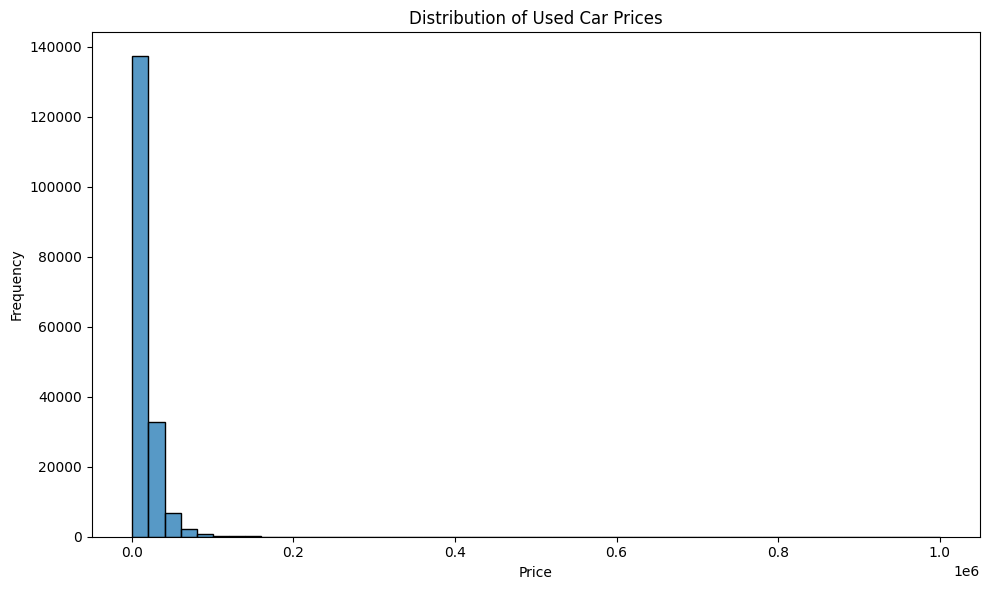

In [5]:
# ============================================
# 4.1 PRICE DISTRIBUTION
# ============================================

plt.figure(figsize=(10, 6))

sns.histplot(data=df, x="price", bins=50)

plt.title("Distribution of Used Car Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

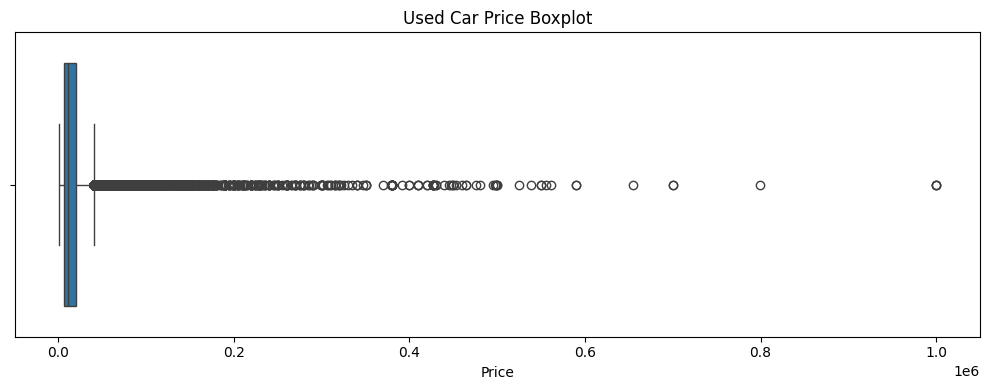

In [6]:
# ============================================
# 4.2 PRICE BOXPLOT
# ============================================

plt.figure(figsize=(10, 4))

sns.boxplot(x=df["price"])

plt.title("Used Car Price Boxplot")
plt.xlabel("Price")

plt.tight_layout()
plt.show()

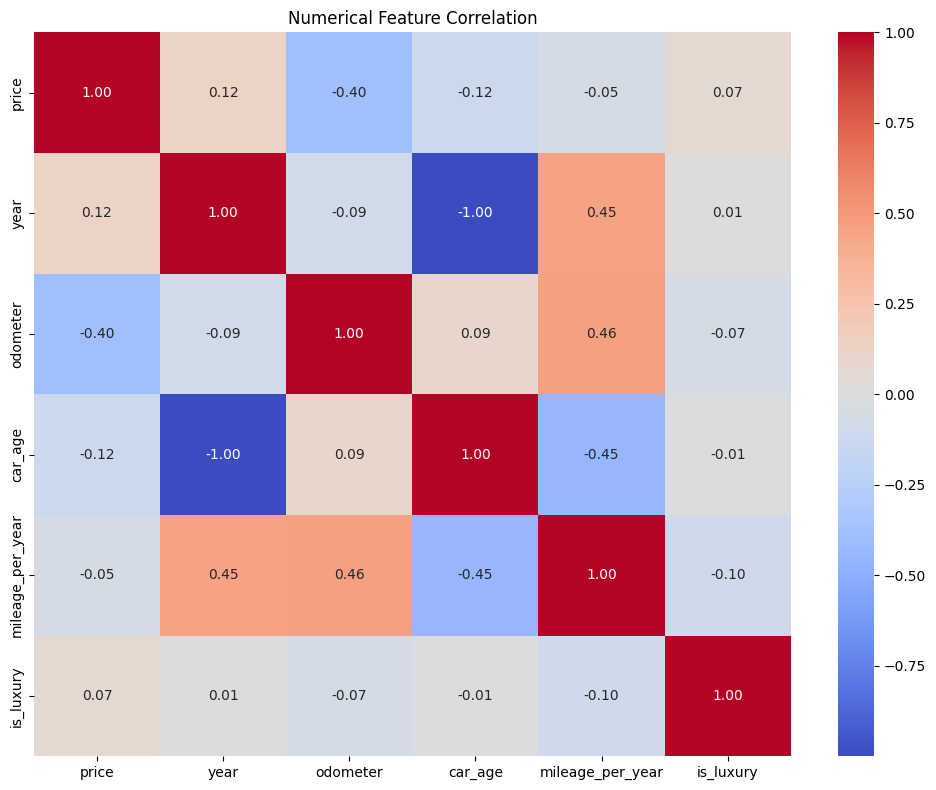

In [7]:
# ============================================
# 4.3 NUMERICAL CORRELATION
# ============================================

numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(10, 8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Numerical Feature Correlation")

plt.tight_layout()
plt.show()

In [8]:
# ============================================
# 5. REGRESSION DATA PREPARATION
# ============================================

# Target variable
y_reg = df["price"]

# Features
X_reg = df.drop(columns=["price", "car_age"], errors="ignore")

print("Regression features:")
print(X_reg.columns.tolist())

print("\nX shape:", X_reg.shape)
print("y shape:", y_reg.shape)

Regression features:
['year', 'manufacturer', 'model', 'condition', 'cylinders', 'fuel', 'odometer', 'title_status', 'transmission', 'drive', 'type', 'paint_color', 'state', 'seller_type', 'mileage_per_year', 'is_luxury']

X shape: (180695, 16)
y shape: (180695,)


In [9]:
# ============================================
# 6. REGRESSION TRAIN/TEST SPLIT
# ============================================

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg,
    y_reg,
    test_size=0.20,
    random_state=42
)

print("Training set:", X_train_reg.shape)
print("Testing set:", X_test_reg.shape)

Training set: (144556, 16)
Testing set: (36139, 16)


In [10]:
# ============================================
# 7. REGRESSION PREPROCESSING
# ============================================

numeric_features_reg = X_train_reg.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features_reg = X_train_reg.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical features:")
print(numeric_features_reg)

print("\nCategorical features:")
print(categorical_features_reg)

# Numerical preprocessing
numeric_transformer_reg = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer_reg = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor_reg = ColumnTransformer([
    ("num", numeric_transformer_reg, numeric_features_reg),
    ("cat", categorical_transformer_reg, categorical_features_reg)
])

Numerical features:
['year', 'odometer', 'mileage_per_year', 'is_luxury']

Categorical features:
['manufacturer', 'model', 'condition', 'cylinders', 'fuel', 'title_status', 'transmission', 'drive', 'type', 'paint_color', 'state', 'seller_type']


In [11]:
# ============================================
# 8. LINEAR REGRESSION MODEL
# ============================================

linear_regression_model = Pipeline([
    ("preprocessing", preprocessor_reg),
    ("model", LinearRegression())
])

print("Linear Regression model is ready.")

Linear Regression model is ready.


In [12]:
# ============================================
# 9. REGRESSION 10-FOLD CROSS-VALIDATION
# ============================================

cv_reg = KFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

reg_cv_results = cross_validate(
    linear_regression_model,
    X_train_reg,
    y_train_reg,
    cv=cv_reg,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    },
    return_train_score=False,
    n_jobs=1
)

# Convert negative errors to positive values
reg_cv_results_df = pd.DataFrame({
    "MAE": -reg_cv_results["test_MAE"],
    "RMSE": -reg_cv_results["test_RMSE"],
    "R2": reg_cv_results["test_R2"]
})

display(reg_cv_results_df)

print("\nAverage 10-fold results:")
print(reg_cv_results_df.mean())

print("\nStandard deviation across folds:")
print(reg_cv_results_df.std())

,MAE,RMSE,R2
0,5794.373954,14572.805570,0.487668
1,5764.346797,13129.339238,0.528811
2,5726.852667,12006.165722,0.529631
3,5849.249224,13474.935836,0.499077
4,5696.131001,11426.216609,0.582512
5,5719.745098,11776.505899,0.539655
6,5758.384017,11836.977855,0.576849
7,5937.343517,14625.530379,0.492970
8,5701.474097,11847.021091,0.587583
9,5737.268455,12331.471630,0.576281



Average 10-fold results:
MAE      5768.516883
RMSE    12702.696983
R2          0.540104
dtype: float64

Standard deviation across folds:
MAE       75.006892
RMSE    1181.562893
R2         0.038878
dtype: float64


In [13]:
# ============================================
# 10. TRAIN LINEAR REGRESSION
# ============================================

linear_regression_model.fit(
    X_train_reg,
    y_train_reg
)

# Predict prices on the unseen test data
y_pred_reg = linear_regression_model.predict(X_test_reg)

print("Linear Regression training complete.")

Linear Regression training complete.


In [14]:
# ============================================
# 11. REGRESSION EVALUATION
# ============================================

reg_mae = mean_absolute_error(y_test_reg, y_pred_reg)

reg_rmse = np.sqrt(
    mean_squared_error(y_test_reg, y_pred_reg)
)

reg_r2 = r2_score(
    y_test_reg,
    y_pred_reg
)

print("LINEAR REGRESSION TEST RESULTS")
print("=" * 40)

print("MAE :", round(reg_mae, 2))
print("RMSE:", round(reg_rmse, 2))
print("R²  :", round(reg_r2, 4))

LINEAR REGRESSION TEST RESULTS
MAE : 5788.95
RMSE: 15349.35
R²  : 0.4491


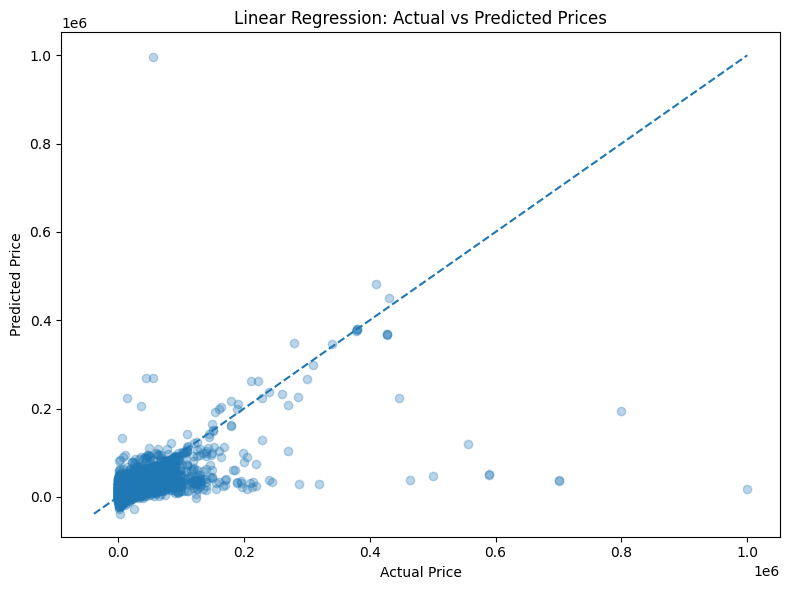

In [15]:
# ============================================
# 12. ACTUAL VS PREDICTED
# ============================================

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_reg,
    y_pred_reg,
    alpha=0.3
)

minimum = min(y_test_reg.min(), y_pred_reg.min())
maximum = max(y_test_reg.max(), y_pred_reg.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Linear Regression: Actual vs Predicted Prices")

plt.tight_layout()
plt.show()

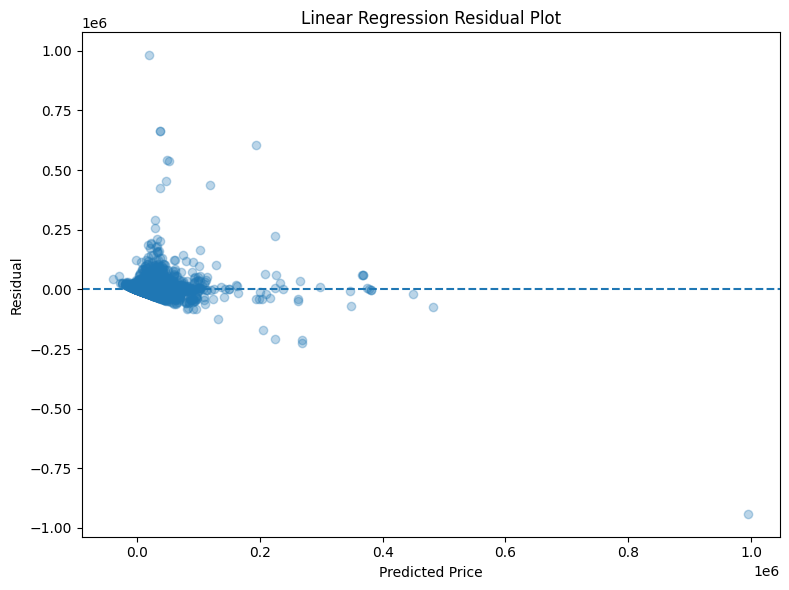

In [16]:
# ============================================
# 13. RESIDUAL ANALYSIS
# ============================================

residuals = y_test_reg - y_pred_reg

plt.figure(figsize=(8, 6))

plt.scatter(
    y_pred_reg,
    residuals,
    alpha=0.3
)

plt.axhline(0, linestyle="--")

plt.xlabel("Predicted Price")
plt.ylabel("Residual")
plt.title("Linear Regression Residual Plot")

plt.tight_layout()
plt.show()

In [17]:
# ============================================
# 14. CREATE PRICE CATEGORIES
# ============================================

df["price_category"] = np.where(
    df["price"] < 7500,
    "Low",
    np.where(
        df["price"] < 16800,
        "Medium",
        "High"
    )
)

print("Category counts:")
print(df["price_category"].value_counts())

print("\nCategory percentages:")
print(
    (df["price_category"].value_counts(normalize=True) * 100).round(2)
)

Category counts:
price_category
Medium    62080
High      60022
Low       58593
Name: count, dtype: int64

Category percentages:
price_category
Medium    34.36
High      33.22
Low       32.43
Name: proportion, dtype: float64


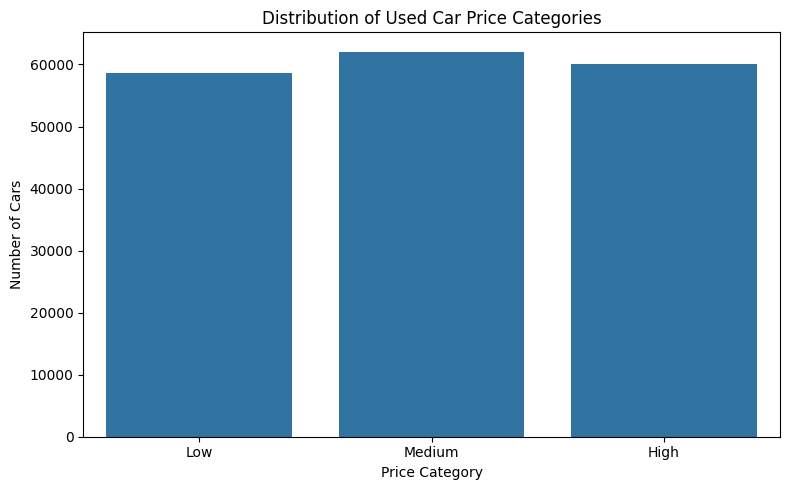

In [18]:
# ============================================
# 14.1 PRICE CATEGORY VISUALIZATION
# ============================================

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="price_category",
    order=["Low", "Medium", "High"]
)

plt.title("Distribution of Used Car Price Categories")
plt.xlabel("Price Category")
plt.ylabel("Number of Cars")

plt.tight_layout()
plt.show()

In [19]:
  # ============================================
# 15. CLASSIFICATION DATA PREPARATION
# ============================================

# Classification target
y_class = df["price_category"]

# Remove BOTH price and price_category from input features
X_class = df.drop(
    columns=["price", "price_category", "car_age"],
    errors="ignore"
)

print("Classification features:")
print(X_class.columns.tolist())

print("\nX shape:", X_class.shape)
print("y shape:", y_class.shape)

Classification features:
['year', 'manufacturer', 'model', 'condition', 'cylinders', 'fuel', 'odometer', 'title_status', 'transmission', 'drive', 'type', 'paint_color', 'state', 'seller_type', 'mileage_per_year', 'is_luxury']

X shape: (180695, 16)
y shape: (180695,)


In [20]:
# ============================================
# 16. CLASSIFICATION TRAIN/TEST SPLIT
# ============================================

X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(
    X_class,
    y_class,
    test_size=0.20,
    random_state=42,
    stratify=y_class
)

print("Training set:", X_train_class.shape)
print("Testing set:", X_test_class.shape)

Training set: (144556, 16)
Testing set: (36139, 16)


In [21]:
# ============================================
# 17. CLASSIFICATION PREPROCESSING
# ============================================

numeric_features_class = X_train_class.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features_class = X_train_class.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical features:")
print(numeric_features_class)

print("\nCategorical features:")
print(categorical_features_class)

# Numerical preprocessing
numeric_transformer_class = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
categorical_transformer_class = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor_class = ColumnTransformer([
    ("num", numeric_transformer_class, numeric_features_class),
    ("cat", categorical_transformer_class, categorical_features_class)
])

Numerical features:
['year', 'odometer', 'mileage_per_year', 'is_luxury']

Categorical features:
['manufacturer', 'model', 'condition', 'cylinders', 'fuel', 'title_status', 'transmission', 'drive', 'type', 'paint_color', 'state', 'seller_type']


In [22]:
# ============================================
# 18. DECISION TREE CLASSIFIER
# ============================================

decision_tree_model = Pipeline([
    ("preprocessing", preprocessor_class),
    ("model", DecisionTreeClassifier(
        criterion="gini",
        max_depth=10,
        random_state=42
    ))
])

print("Decision Tree Classifier is ready.")

Decision Tree Classifier is ready.


In [23]:
# ============================================
# 19. CLASSIFICATION 10-FOLD CROSS-VALIDATION
# ============================================

cv_class = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

class_cv_results = cross_validate(
    decision_tree_model,
    X_train_class,
    y_train_class,
    cv=cv_class,
    scoring={
        "Accuracy": "accuracy",
        "Precision": "precision_weighted",
        "Recall": "recall_weighted",
        "F1": "f1_weighted"
    },
    return_train_score=False,
    n_jobs=1
)

class_cv_results_df = pd.DataFrame({
    "Accuracy": class_cv_results["test_Accuracy"],
    "Precision": class_cv_results["test_Precision"],
    "Recall": class_cv_results["test_Recall"],
    "F1": class_cv_results["test_F1"]
})

display(class_cv_results_df)

print("\nAverage 10-fold results:")
display(class_cv_results_df.mean())

print("\nStandard deviation across folds:")
display(class_cv_results_df.std())

,Accuracy,Precision,Recall,F1
0,0.714928,0.716053,0.714928,0.715452
1,0.709048,0.709858,0.709048,0.709399
2,0.713960,0.713651,0.713960,0.713801
3,0.711815,0.714368,0.711815,0.712897
4,0.714305,0.712289,0.714305,0.713073
5,0.710639,0.712203,0.710639,0.711279
6,0.718782,0.718576,0.718782,0.718670
7,0.721411,0.720997,0.721411,0.721198
8,0.718852,0.718956,0.718852,0.718871
9,0.714078,0.714886,0.714078,0.714400



Average 10-fold results:


,0
Accuracy,0.714782
Precision,0.715184
Recall,0.714782
F1,0.714904



Standard deviation across folds:


,0
Accuracy,0.003898
Precision,0.003480
Recall,0.003898
F1,0.003684


In [24]:
# ============================================
# 20. TRAIN DECISION TREE
# ============================================

decision_tree_model.fit(
    X_train_class,
    y_train_class
)

y_pred_class = decision_tree_model.predict(X_test_class)

print("Decision Tree training complete.")

Decision Tree training complete.


In [25]:
# ============================================
# 21. CLASSIFICATION EVALUATION
# ============================================

class_accuracy = accuracy_score(
    y_test_class,
    y_pred_class
)

class_precision = precision_score(
    y_test_class,
    y_pred_class,
    average="weighted",
    zero_division=0
)

class_recall = recall_score(
    y_test_class,
    y_pred_class,
    average="weighted",
    zero_division=0
)

class_f1 = f1_score(
    y_test_class,
    y_pred_class,
    average="weighted",
    zero_division=0
)

print("DECISION TREE TEST RESULTS")
print("=" * 40)

print("Accuracy :", round(class_accuracy, 4))
print("Precision:", round(class_precision, 4))
print("Recall   :", round(class_recall, 4))
print("F1-score :", round(class_f1, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test_class,
        y_pred_class,
        zero_division=0
    )
)

DECISION TREE TEST RESULTS
Accuracy : 0.7189
Precision: 0.7206
Recall   : 0.7189
F1-score : 0.7197

Classification Report:
              precision    recall  f1-score   support

        High       0.82      0.79      0.80     12004
         Low       0.73      0.74      0.74     11719
      Medium       0.62      0.63      0.62     12416

    accuracy                           0.72     36139
   macro avg       0.72      0.72      0.72     36139
weighted avg       0.72      0.72      0.72     36139



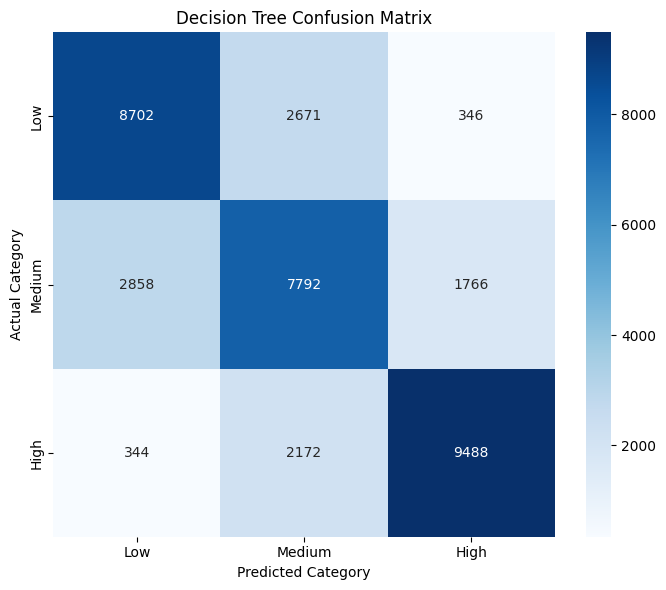

In [26]:
# ============================================
# 22. CONFUSION MATRIX
# ============================================

cm = confusion_matrix(
    y_test_class,
    y_pred_class,
    labels=["Low", "Medium", "High"]
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low", "Medium", "High"],
    yticklabels=["Low", "Medium", "High"]
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("Decision Tree Confusion Matrix")

plt.tight_layout()
plt.show()

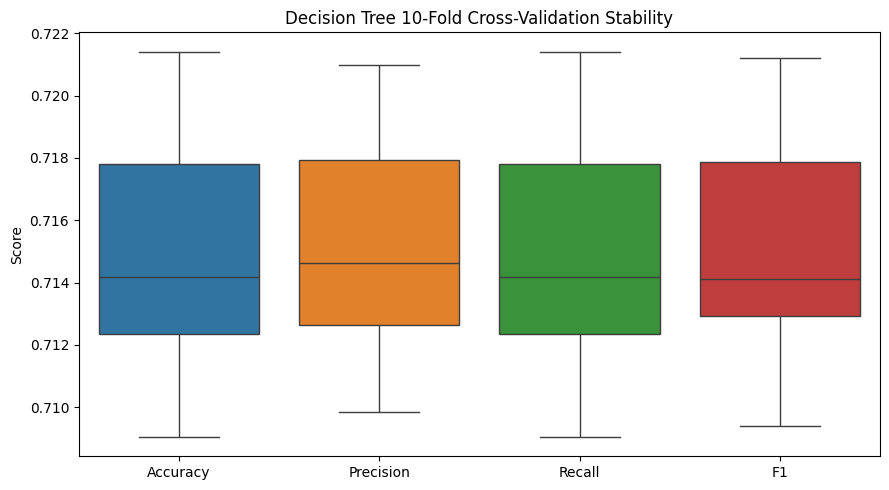

In [27]:
# ============================================
# 23. CROSS-VALIDATION STABILITY
# ============================================

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=class_cv_results_df[
        ["Accuracy", "Precision", "Recall", "F1"]
    ]
)

plt.title("Decision Tree 10-Fold Cross-Validation Stability")
plt.ylabel("Score")

plt.tight_layout()
plt.show()

In [28]:
# ============================================
# 24. REGRESSION CROSS-VALIDATION SUMMARY
# ============================================

regression_summary = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R²"],
    "Mean CV Score": [
        reg_cv_results_df["MAE"].mean(),
        reg_cv_results_df["RMSE"].mean(),
        reg_cv_results_df["R2"].mean()
    ],
    "Standard Deviation": [
        reg_cv_results_df["MAE"].std(),
        reg_cv_results_df["RMSE"].std(),
        reg_cv_results_df["R2"].std()
]
})

display(regression_summary)

,Metric,Mean CV Score,Standard Deviation
0,MAE,5768.516883,75.006892
1,RMSE,12702.696983,1181.562893
2,R²,0.540104,0.038878


In [29]:
# ============================================
# 25. CLASSIFICATION CROSS-VALIDATION SUMMARY
# ============================================

classification_summary = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Mean CV Score": [
        class_cv_results_df["Accuracy"].mean(),
        class_cv_results_df["Precision"].mean(),
        class_cv_results_df["Recall"].mean(),
        class_cv_results_df["F1"].mean()
    ],
    "Standard Deviation": [
        class_cv_results_df["Accuracy"].std(),
        class_cv_results_df["Precision"].std(),
        class_cv_results_df["Recall"].std(),
        class_cv_results_df["F1"].std()
]
})

display(classification_summary)

,Metric,Mean CV Score,Standard Deviation
0,Accuracy,0.714782,0.003898
1,Precision,0.715184,0.003480
2,Recall,0.714782,0.003898
3,F1-score,0.714904,0.003684


In [30]:
# ============================================
# 26. FINAL MODEL RESULTS TABLE
# ============================================

final_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree Classifier"
    ],
    "Task": [
        "Regression",
        "Classification"
    ],
    "Target": [
        "Price",
        "Price Category"
    ],
    "Main Test Metric": [
        "RMSE",
        "Accuracy"
    ],
    "Test Result": [
        reg_rmse,
        class_accuracy
    ]
})

display(final_results)

,Model,Task,Target,Main Test Metric,Test Result
0,Linear Regression,Regression,Price,RMSE,15349.347382
1,Decision Tree Classifier,Classification,Price Category,Accuracy,0.718946


In [31]:
# ============================================
# 27. PRELIMINARY GO / NO-GO
# ============================================

print("FINAL MODEL EVALUATION")
print("=" * 50)

print("\nLinear Regression")
print("MAE :", reg_mae)
print("RMSE:", reg_rmse)
print("R²  :", reg_r2)

print("\nDecision Tree Classifier")
print("Accuracy :", class_accuracy)
print("Precision:", class_precision)
print("Recall   :", class_recall)
print("F1-score :", class_f1)

print("\nCross-validation stability")

print("Regression RMSE standard deviation:",
      reg_cv_results_df["RMSE"].std())

print("Classification accuracy standard deviation:",
      class_cv_results_df["Accuracy"].std())

print("\nFinal Go/No-Go decision must be based on:")
print("- Model performance")
print("- Cross-validation stability")
print("- Business requirements")
print("- Limitations and risks")
print("- Whether the model is suitable for real-world use")

FINAL MODEL EVALUATION

Linear Regression
MAE : 5788.952739293335
RMSE: 15349.34738244219
R²  : 0.44914379691565653

Decision Tree Classifier
Accuracy : 0.7189462907108664
Precision: 0.7206106749139047
Recall   : 0.7189462907108664
F1-score : 0.7196692437110025

Cross-validation stability
Regression RMSE standard deviation: 1181.562892840198
Classification accuracy standard deviation: 0.0038983573542348098

Final Go/No-Go decision must be based on:
- Model performance
- Cross-validation stability
- Business requirements
- Limitations and risks
- Whether the model is suitable for real-world use


In [32]:
# ============================================
# 28. GRID SEARCH - LINEAR REGRESSION
# ============================================

from sklearn.model_selection import GridSearchCV

lr_param_grid = {
    "model__fit_intercept": [True, False]
}

lr_grid_search = GridSearchCV(
    estimator=linear_regression_model,
    param_grid=lr_param_grid,
    scoring="neg_mean_absolute_error",
    cv=10,
    n_jobs=-1
)

# Train Grid Search
lr_grid_search.fit(X_train_reg, y_train_reg)

# Display results
print("LINEAR REGRESSION - GRID SEARCH")
print("=" * 40)
print("Best Parameters:", lr_grid_search.best_params_)
print("Best CV MAE:", round(-lr_grid_search.best_score_, 2))

LINEAR REGRESSION - GRID SEARCH
Best Parameters: {'model__fit_intercept': False}
Best CV MAE: 5771.38


In [44]:
# ============================================
# 29. GRID SEARCH - DECISION TREE CLASSIFIER
# ============================================

from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Identify categorical and numerical columns
categorical_columns = X_train_class.select_dtypes(
    include=["object", "category"]
).columns

numerical_columns = X_train_class.select_dtypes(
    include=["int64", "float64"]
).columns

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_columns),
        ("numerical", Pipeline([
            ("imputer", SimpleImputer(strategy="median"))
        ]), numerical_columns)
    ]
)

# Decision Tree Pipeline
dt_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", DecisionTreeClassifier(random_state=42))
])

# Parameters to test
dt_param_grid = {
    "model__criterion": ["gini"],
    "model__max_depth": [5, 10],
    "model__min_samples_leaf": [5]
}

# Grid Search
dt_grid_search = GridSearchCV(
    estimator=dt_pipeline,
    param_grid=dt_param_grid,
    scoring="accuracy",
    cv=3,
    n_jobs=1
)

# Train
dt_grid_search.fit(X_train_class, y_train_class)

# Results
print("DECISION TREE - GRID SEARCH")
print("=" * 40)
print("Best Parameters:", dt_grid_search.best_params_)
print("Best CV Accuracy:", round(dt_grid_search.best_score_, 4))

DECISION TREE - GRID SEARCH
Best Parameters: {'model__criterion': 'gini', 'model__max_depth': 10, 'model__min_samples_leaf': 5}
Best CV Accuracy: 0.7125
